Liczba wierszy przed usunięciem: 238098
Brakujące wartości:
filename               0
extension              0
blockiness_0           0
blockiness_1           0
blockiness_2           0
blockiness_3           0
blockiness_4           0
blockiness_5           0
blockiness_6           0
blockiness_7           0
blockiness_max         0
blockiness_mean        0
blockiness_std         0
energy_mean            0
energy_std             0
estimated_quality      0
psnr                 406
dtype: int64

Liczba wierszy po usunięciu: 237692

Zakres jakości: 10 - 95
Rozkład jakości:
quality
10    11276
20    11300
30    11303
40    11302
50    11304
60    11299
70    11304
75    11323
78    11296
80    11305
82    11323
84    11328
86    11325
88    11338
89    11338
90    11338
91    11338
92    11338
93    11338
94    11338
95    11338
Name: count, dtype: int64

Zbiór treningowy: 142614 próbek
Zbiór walidacyjny: 47539 próbek
Zbiór testowy: 47539 próbek

Trening modelu: Linear Regression

Zakres j

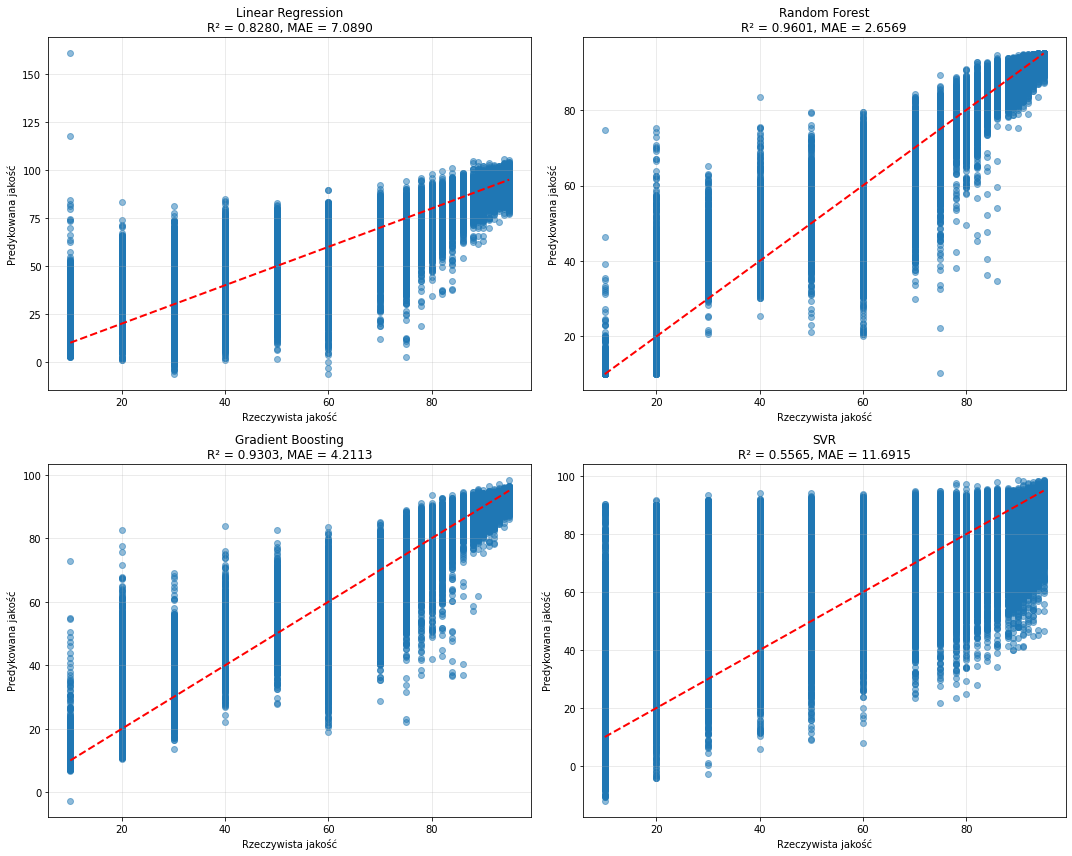


Najlepszy model: Random Forest
R² na zbiorze testowym: 0.9601


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import re

# Load data
df = pd.read_csv('results_240k_one_compression_filtered.csv')

print(f"Number of rows before removal: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")

# Remove rows with incomplete data
df = df.dropna()

print(f"\nNumber of rows after removal: {len(df)}")

# Extract quality from the filename (e.g. "..._q10" -> 10)
df['quality'] = df['filename'].str.extract(r'_q(\d+)')[0].astype(int)

print(f"\nQuality range: {df['quality'].min()} - {df['quality'].max()}")
print(f"Quality distribution:\n{df['quality'].value_counts().sort_index()}")

# Prepare data - remove columns unrelated to prediction
X = df.drop(['filename', 'extension', 'estimated_quality', 'quality'], axis=1)
y = df['quality']

# Split into training, validation, and test sets (60%, 20%, 20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"\nTraining set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

# Model definitions
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'SVR': SVR(kernel='rbf')
}

# Train and evaluate models
results = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training model: {name}")
    print('='*50)
    
    # Train
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred_train = model.predict(X_train)
    y_pred_val = model.predict(X_val)
    y_pred_test = model.predict(X_test)
    
    # Metrics
    results[name] = {
        'train_mse': mean_squared_error(y_train, y_pred_train),
        'train_mae': mean_absolute_error(y_train, y_pred_train),
        'train_r2': r2_score(y_train, y_pred_train),
        'val_mse': mean_squared_error(y_val, y_pred_val),
        'val_mae': mean_absolute_error(y_val, y_pred_val),
        'val_r2': r2_score(y_val, y_pred_val),
        'test_mse': mean_squared_error(y_test, y_pred_test),
        'test_mae': mean_absolute_error(y_test, y_pred_test),
        'test_r2': r2_score(y_test, y_pred_test),
        'model': model
    }
    
    print(f"Train - MSE: {results[name]['train_mse']:.4f}, MAE: {results[name]['train_mae']:.4f}, R²: {results[name]['train_r2']:.4f}")
    print(f"Val   - MSE: {results[name]['val_mse']:.4f}, MAE: {results[name]['val_mae']:.4f}, R²: {results[name]['val_r2']:.4f}")
    print(f"Test  - MSE: {results[name]['test_mse']:.4f}, MAE: {results[name]['test_mae']:.4f}, R²: {results[name]['test_r2']:.4f}")

# Results summary
print(f"\n{'='*50}")
print("RESULTS SUMMARY (test set)")
print('='*50)

results_df = pd.DataFrame({
    name: {
        'MSE': res['test_mse'],
        'MAE': res['test_mae'],
        'R²': res['test_r2']
    }
    for name, res in results.items()
}).T

print(results_df.sort_values('R²', ascending=False))

# Saving the model

In [ ]:
# import joblib
# import os

# # Create the models directory if it does not exist
# os.makedirs('models', exist_ok=True)

# # Save all models to files
# for name, res in results.items():
#     # Convert the name to a filename (remove spaces)
#     filename = os.path.join('models', name.replace(' ', '_').lower() + '_compression_model.pkl')
#     joblib.dump(res['model'], filename)
#     print(f"Saved model: {name} -> {filename}")

# # Also save the best model separately
# best_model_path = os.path.join('models', 'best_compression_model.pkl')
# joblib.dump(results[best_model_name]['model'], best_model_path)
# print(f"\nBest model ({best_model_name}) was also saved as: {best_model_path}")

Zapisano model: Linear Regression -> models\linear_regression_compression_model.pkl
Zapisano model: Random Forest -> models\random_forest_compression_model.pkl
Zapisano model: Gradient Boosting -> models\gradient_boosting_compression_model.pkl
Zapisano model: SVR -> models\svr_compression_model.pkl
Zapisano model: Random Forest -> models\random_forest_compression_model.pkl
Zapisano model: Gradient Boosting -> models\gradient_boosting_compression_model.pkl
Zapisano model: SVR -> models\svr_compression_model.pkl

Najlepszy model (Random Forest) zapisano również jako: models\best_compression_model.pkl

Najlepszy model (Random Forest) zapisano również jako: models\best_compression_model.pkl


# Loading and evaluating saved models

In [ ]:
import joblib
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import re

# Load data
df = pd.read_csv('results_240k_one_compression_filtered.csv')

# Randomly select 10% of the data
df = df.sample(frac=0.10, random_state=42)



print(f"Number of rows before removal: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")

# Remove rows with incomplete data
df = df.dropna()

print(f"\nNumber of rows after removal: {len(df)}")

# Extract quality from the filename (e.g. "..._q10" -> 10)
df['quality'] = df['filename'].str.extract(r'_q(\d+)')[0].astype(int)

print(f"\nQuality range: {df['quality'].min()} - {df['quality'].max()}")
print(f"Quality distribution:\n{df['quality'].value_counts().sort_index()}")

# Prepare data - remove columns unrelated to prediction
X = df.drop(['filename', 'extension', 'estimated_quality', 'quality'], axis=1)
y = df['quality']

# Split into training, validation, and test sets (60%, 20%, 20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"\nTraining set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

# Model definitions
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'SVR': SVR(kernel='rbf')
}

# Train and evaluate models
results = {}

# Find all saved models (excluding best_compression_model.pkl)
model_files = [f for f in glob.glob(os.path.join('models', '*_compression_model.pkl')) 
               if 'best_compression_model.pkl' not in f]

if not model_files:
    print("No saved models found in the 'models/' directory")
else:
    print(f"Found {len(model_files)} models\n")
    
    # Dictionary for loaded models
    loaded_results = {}
    
    for model_path in model_files:
        # Extract the model name from the filename
        model_filename = os.path.basename(model_path)
        model_name = model_filename.replace('_compression_model.pkl', '').replace('_', ' ').title()
        
        # Special handling for SVR - preserve capitalization
        if model_name.lower() == 'svr':
            model_name = 'SVR'
        
        print(f"Loading model: {model_name}")
        
        # Load model
        loaded_model = joblib.load(model_path)
        
        # Predictions on all sets
        y_pred_train = loaded_model.predict(X_train)
        y_pred_val = loaded_model.predict(X_val)
        y_pred_test = loaded_model.predict(X_test)
        
        # Compute metrics
        loaded_results[model_name] = {
            'train_mse': mean_squared_error(y_train, y_pred_train),
            'train_mae': mean_absolute_error(y_train, y_pred_train),
            'train_r2': r2_score(y_train, y_pred_train),
            'val_mse': mean_squared_error(y_val, y_pred_val),
            'val_mae': mean_absolute_error(y_val, y_pred_val),
            'val_r2': r2_score(y_val, y_pred_val),
            'test_mse': mean_squared_error(y_test, y_pred_test),
            'test_mae': mean_absolute_error(y_test, y_pred_test),
            'test_r2': r2_score(y_test, y_pred_test),
            'model': loaded_model
        }
        
        print(f"Train - MSE: {loaded_results[model_name]['train_mse']:.4f}, MAE: {loaded_results[model_name]['train_mae']:.4f}, R²: {loaded_results[model_name]['train_r2']:.4f}")
        print(f"Val   - MSE: {loaded_results[model_name]['val_mse']:.4f}, MAE: {loaded_results[model_name]['val_mae']:.4f}, R²: {loaded_results[model_name]['val_r2']:.4f}")
        print(f"Test  - MSE: {loaded_results[model_name]['test_mse']:.4f}, MAE: {loaded_results[model_name]['test_mae']:.4f}, R²: {loaded_results[model_name]['test_r2']:.4f}")
        print()
    
    # Results summary
    print(f"{'='*50}")
    print("LOADED MODELS RESULTS SUMMARY (test set)")
    print('='*50)
    
    loaded_results_df = pd.DataFrame({
        name: {
            'MSE': res['test_mse'],
            'MAE': res['test_mae'],
            'R²': res['test_r2']
        }
        for name, res in loaded_results.items()
    }).T
    
    print(loaded_results_df.sort_values('R²', ascending=False))

Liczba wierszy przed usunięciem: 23810
Brakujące wartości:
filename              0
extension             0
blockiness_0          0
blockiness_1          0
blockiness_2          0
blockiness_3          0
blockiness_4          0
blockiness_5          0
blockiness_6          0
blockiness_7          0
blockiness_max        0
blockiness_mean       0
blockiness_std        0
energy_mean           0
energy_std            0
estimated_quality     0
psnr                 26
dtype: int64

Liczba wierszy po usunięciu: 23784

Zakres jakości: 10 - 95
Rozkład jakości:
quality
10    1091
20    1131
30    1190
40    1079
50    1174
60    1121
70    1161
75    1130
78    1115
80    1152
82    1164
84    1103
86    1118
88    1082
89    1125
90    1149
91    1082
92    1104
93    1144
94    1216
95    1153
Name: count, dtype: int64

Zbiór treningowy: 14270 próbek
Zbiór walidacyjny: 4757 próbek
Zbiór testowy: 4757 próbek
Znaleziono 4 modeli

Wczytywanie modelu: Gradient Boosting
Train - MSE: 46.7807, MAE: 4

In [ ]:
import joblib
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import re

best_model_path = os.path.join('models', 'best_compression_model.pkl')
# Load the saved model
loaded_model = joblib.load(best_model_path)

# Prediction on the test set
# y_pred_loaded = loaded_model.predict(X_val)

# # Compute metrics for the loaded model
# loaded_mse = mean_squared_error(y_val, y_pred_loaded)
# loaded_mae = mean_absolute_error(y_val, y_pred_loaded)
# loaded_r2 = r2_score(y_val, y_pred_loaded)

# # print(f"Loaded model: {best_model_name}")
# print(f"MSE: {loaded_mse:.4f}")
# print(f"MAE: {loaded_mae:.4f}")
# print(f"R²: {loaded_r2:.4f}")

# # Example prediction for the first 5 samples
# print(f"\nExample predictions (first 5 samples):")
# print(f"{'Actual quality':<20} {'Predicted quality':<20}")
# print("-" * 40)
# for real, pred in zip(y_val.head(25), y_pred_loaded[:25]):
#     print(f"{real:<20} {pred:<20.2f}")

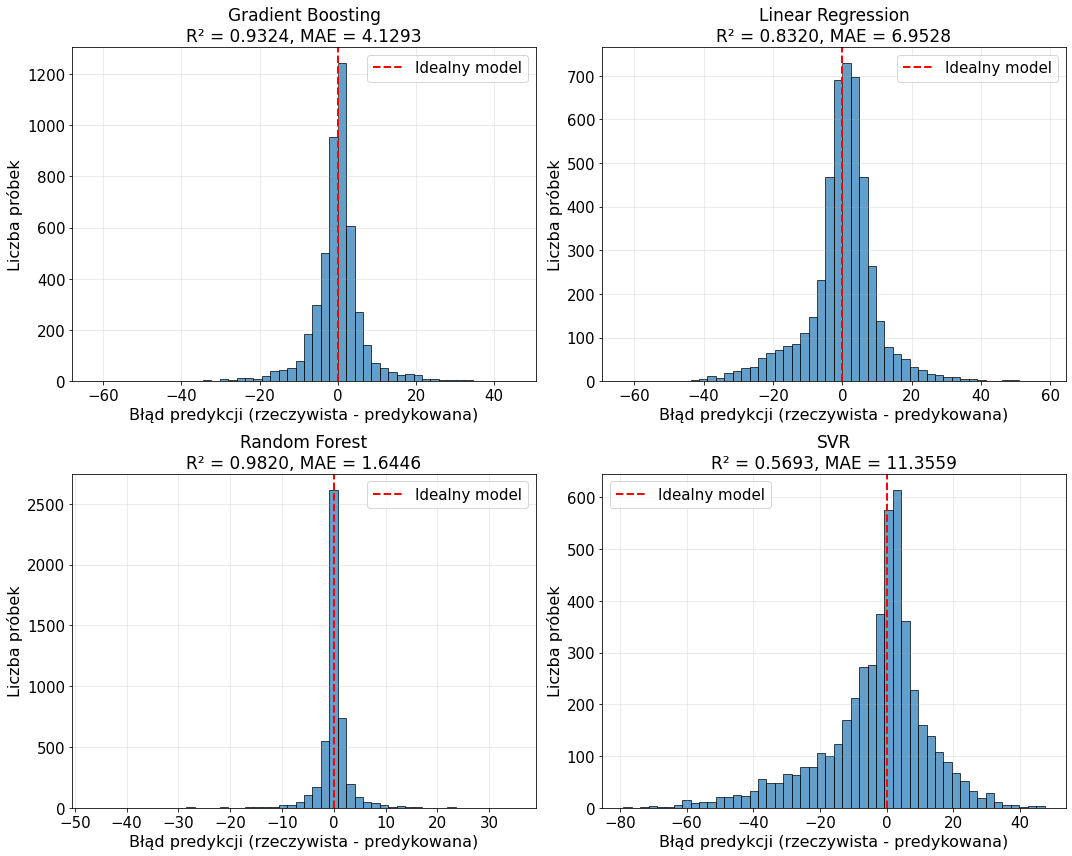

In [ ]:
# Font size control for plots
FONT_SIZE = 16

# Visualization of results with histograms
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, (name, res) in enumerate(loaded_results.items()):
    y_pred_test = res['model'].predict(X_test)
    
    # Calculate prediction errors
    errors = y_test.values - y_pred_test
    
    # Error histogram
    axes[idx].hist(errors, bins=50, alpha=0.7, edgecolor='black')
    axes[idx].axvline(x=0, color='r', linestyle='--', lw=2, label='Ideal model')
    axes[idx].set_xlabel('Prediction error (actual - predicted)', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Number of samples', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["test_r2"]:.4f}, MAE = {res["test_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)

plt.tight_layout()
plt.show()


# Validation boxplots

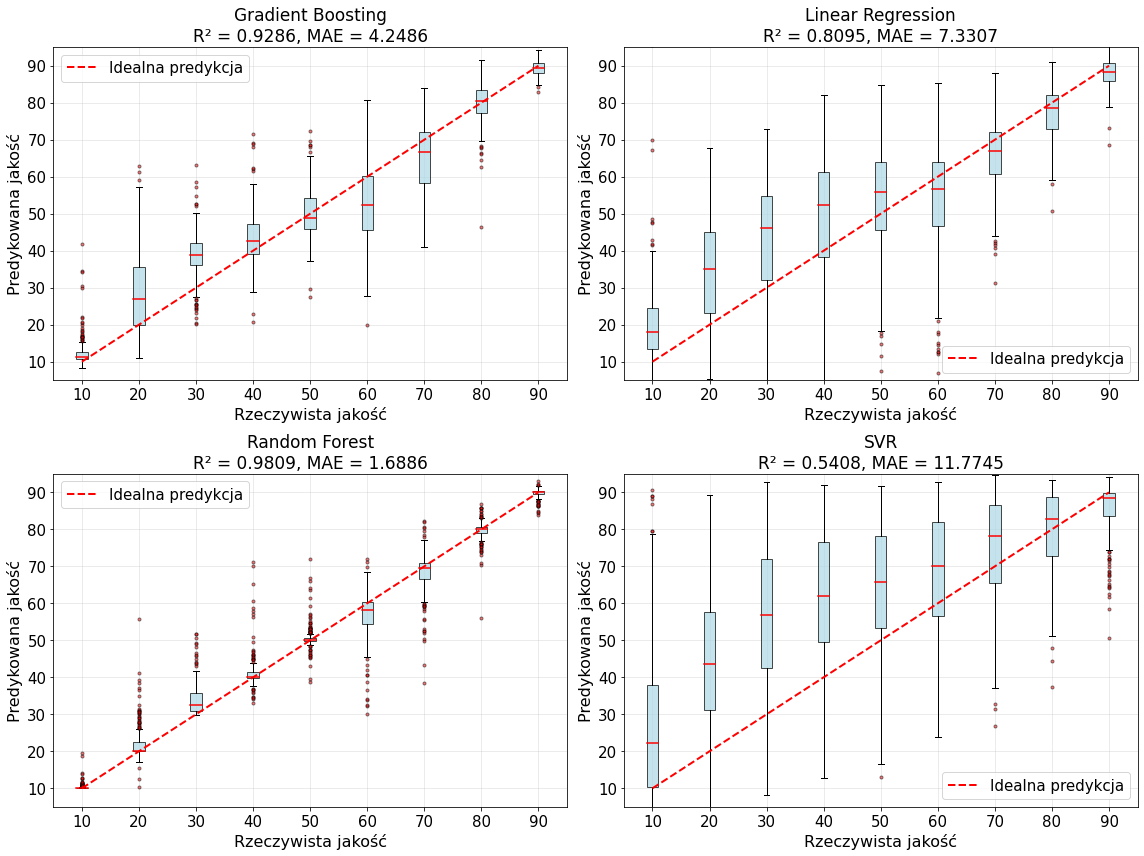

Wykres zapisany jako 'models_validation_comparison_boxplot_10percent.png'
Liczba próbek: 4757 (10% z 4757)


In [ ]:
# Randomly select 10% of the validation data
sample_size = int(len(X_val) * 1)
sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

X_val_sample = X_val.iloc[sample_indices]
y_val_sample = y_val.iloc[sample_indices]

# Visualize models on 10% of validation data - boxplot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for idx, (name, res) in enumerate(loaded_results.items()):
    # Get predictions for sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = axes[idx].boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=True,
                            medianprops=dict(color='red', linewidth=1.5),
                            flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    axes[idx].plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    axes[idx].set_xlabel('Actual quality', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)
    axes[idx].set_xlim(5, 95)
    axes[idx].set_ylim(5, 95)

plt.tight_layout()
# plt.savefig('models_validation_comparison_boxplot_10percent.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as 'models_validation_comparison_boxplot_10percent.png'")
print(f"Number of samples: {sample_size} (10% of {len(X_val)})")


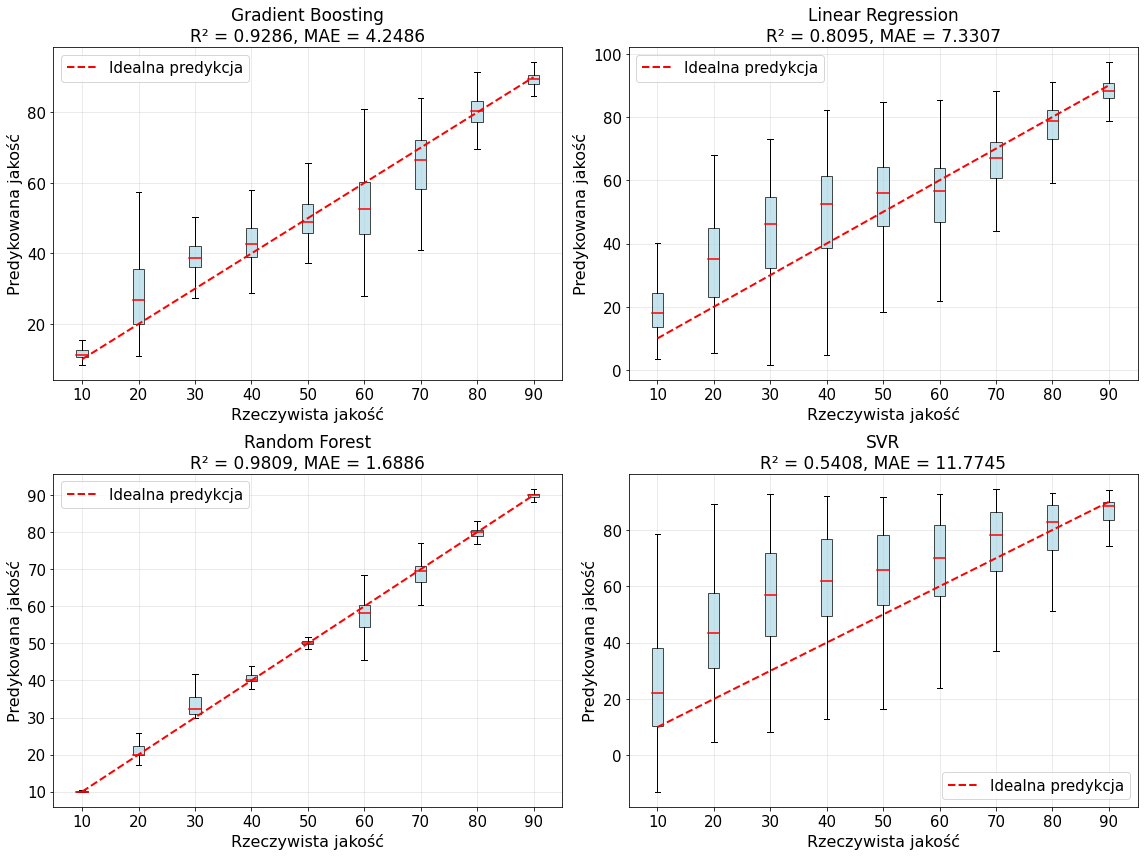

Wykres zapisany jako 'models_validation_comparison_boxplot_linear_10percent.png'
Liczba próbek: 4757 (10% z 4757)


In [ ]:
# Randomly select 10% of the validation data
# sample_size = int(len(X_val) * 0.1)
# sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

# X_val_sample = X_val.iloc[sample_indices]
# y_val_sample = y_val.iloc[sample_indices]

# Visualize models on 10% of validation data - linear scale
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for idx, (name, res) in enumerate(loaded_results.items()):
    # Get predictions for sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = axes[idx].boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=False,
                            medianprops=dict(color='red', linewidth=1.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    axes[idx].plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    axes[idx].set_xlabel('Actual quality', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)

plt.tight_layout()
# plt.savefig('models_validation_comparison_boxplot_linear_10percent.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as 'models_validation_comparison_boxplot_linear_10percent.png'")
print(f"Number of samples: {sample_size} (10% of {len(X_val)})")


# Test on JFIF (ThisPersonDoesNotExist)

# Moved to ML-compression-tests